# Crop Disease Classification - End-to-End ML Pipeline

**Use case.** Tomato is one of the most widely grown vegetables in Rwanda and across Africa, and leaf diseases such as blights, leaf mold and viral infections can wipe out a large share of a harvest when they are caught late. A farmer (or extension officer) should be able to photograph a tomato leaf and get an instant diagnosis.

**Data.** The tomato subset of the PlantVillage dataset (without augmentation): 18,145 RGB leaf images in 10 classes (9 diseases and healthy): bacterial spot, early blight, late blight, leaf mold, Septoria leaf spot, spider mites, target spot, Yellow Leaf Curl Virus, mosaic virus and healthy.

**Environment.** This notebook was run on Kaggle (GPU T4), so the paths point to the Kaggle environment (`/kaggle/input`, `/kaggle/working`).

| # | Stage | Steps |
|---|---|---|
| 1 | Data acquisition | load the tomato classes, build an inventory, remove corrupt files and duplicates |
| 2 | Data splitting | stratified 70/15/15 split into train, validation and test |
| 3 | Exploratory analysis | class balance, image size, colour, lesion coverage, brightness, texture, with interpretations |
| 4 | Preprocessing | resizing, normalisation, augmentation, class weights, `tf.data` pipelines |
| 5 | Model creation | baseline CNN vs MobileNetV2 transfer learning (hyperparameter search, L2, dropout, Adam, early stopping, learning-rate scheduling, fine-tuning) |
| 6 | Model testing | accuracy, loss, precision, recall, F1, top-3 accuracy, ROC-AUC, confusion matrix |
| 7 | Prediction | single-image prediction function |
| 8 | Retraining | fine-tune the saved model on new data and replace it only if it performs at least as well |
| 9 | Summary | main findings and results |

## 0. Setup

This notebook was run on Kaggle (GPU T4); paths point to the Kaggle environment.

In [96]:
import os, json, random, shutil, zipfile, hashlib, time, warnings
from pathlib import Path
from collections import Counter
import io
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_auc_score,
                             top_k_accuracy_score, log_loss, roc_curve)

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import tensorflow as tf
import keras
from keras import layers, regularizers, callbacks
from keras.applications import mobilenet_v2

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 60)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [10]:
PROJECT_ROOT = Path("/kaggle/working")
INPUT_DIR    = Path("/kaggle/input/datasets/etiennekagaba/plantvillage-tomato")
DATA_DIR     = PROJECT_ROOT / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_DIR, VAL_DIR, TEST_DIR = DATA_DIR / "train", DATA_DIR / "validation", DATA_DIR / "test"
UPLOAD_DIR   = DATA_DIR / "uploads"
UPLOAD_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR   = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "crop_disease_mobilenetv2"
MODEL_PATH = MODELS_DIR / f"{MODEL_NAME}.h5"
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

EPOCHS_BASELINE = 8
EPOCHS_HEAD     = 10
EPOCHS_FINETUNE = 10
HPARAM_EPOCHS   = 3

CROP_PREFIX = "Tomato___"
AUTOTUNE = tf.data.AUTOTUNE

## 1. Data acquisition

I'm using the tomato classes from the PlantVillage dataset (without augmentation), originally from
[Mendeley Data](https://data.mendeley.com/datasets/tywbtsjrjv/1). I uploaded the 10 tomato class
folders to Kaggle as a dataset, so they are already extracted under `/kaggle/input`.

Steps:
1. list the class folders
2. build a table with one row per image (path, class, disease)
3. check for corrupt and duplicate images

In [5]:
CLASS_ROOT = INPUT_DIR
SELECTED_CLASSES = sorted(d.name for d in CLASS_ROOT.iterdir() if d.is_dir())
print(len(SELECTED_CLASSES), "classes")
for c in SELECTED_CLASSES:
    print(" ", c)

def parse_class(name):
    # 'Tomato___Late_blight' -> ('Tomato', 'Late blight')
    crop, _, disease = name.partition("___")
    disease = disease.replace("_", " ").replace("Tomato ", "").split(" Two-spotted")[0]
    return crop, disease[0].upper() + disease[1:]

# short names and colours for plots
SHORT = pd.Series({c: parse_class(c)[1] for c in SELECTED_CLASSES})
PALETTE = dict(zip(SELECTED_CLASSES, sns.color_palette("tab10", len(SELECTED_CLASSES)).as_hex()))
PALETTE["Tomato___healthy"] = "#2a9d8f"

def sample_per_class(df, n, seed=SEED):
    return pd.concat([g.sample(min(len(g), n), random_state=seed) for _, g in df.groupby("label")])

10 classes
  Tomato___Bacterial_spot
  Tomato___Early_blight
  Tomato___Late_blight
  Tomato___Leaf_Mold
  Tomato___Septoria_leaf_spot
  Tomato___Spider_mites Two-spotted_spider_mite
  Tomato___Target_Spot
  Tomato___Tomato_Yellow_Leaf_Curl_Virus
  Tomato___Tomato_mosaic_virus
  Tomato___healthy


In [6]:
records = []
for cls in SELECTED_CLASSES:
    crop, disease = parse_class(cls)
    for f in (CLASS_ROOT / cls).iterdir():
        if f.suffix.lower() == ".jpg":
            records.append({"path": str(f), "label": cls, "crop": crop, "disease": disease,
                            "is_healthy": disease.lower() == "healthy"})

inventory = pd.DataFrame(records)
print(f"{len(inventory):,} images in {inventory.label.nunique()} classes")
inventory.sample(5, random_state=SEED)

18,159 images in 10 classes


,path,label,crop,disease,is_healthy
11878,/kaggle/input/datasets/etiennekagaba/plantvillage-tomato...,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato,Yellow Leaf Curl Virus,False
9044,/kaggle/input/datasets/etiennekagaba/plantvillage-tomato...,Tomato___Spider_mites Two-spotted_spider_mite,Tomato,Spider mites,False
2189,/kaggle/input/datasets/etiennekagaba/plantvillage-tomato...,Tomato___Early_blight,Tomato,Early blight,False
13110,/kaggle/input/datasets/etiennekagaba/plantvillage-tomato...,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Tomato,Yellow Leaf Curl Virus,False
17478,/kaggle/input/datasets/etiennekagaba/plantvillage-tomato...,Tomato___healthy,Tomato,Healthy,True


### 1.1 Data validation and cleaning
Every file is opened with Pillow to catch truncated or corrupt images, and we record width, height, file size and an MD5 hash. Exact duplicates (same hash) are dropped so the same image cannot end up in both train and test, which would inflate the test scores.

In [9]:
def inspect_image(path):
    try:
        data = Path(path).read_bytes()
        md5 = hashlib.md5(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            im.verify()
        with Image.open(io.BytesIO(data)) as im:
            w, h = im.size
            mode = im.mode
        return w, h, mode, len(data), md5, True
    except Exception:
        return None, None, None, None, None, False

t0 = time.time()
with ThreadPoolExecutor(max_workers=16) as ex:
    results = list(tqdm(ex.map(inspect_image, inventory.path), total=len(inventory), desc="Inspecting"))

meta_cols = ["width", "height", "mode", "bytes", "md5", "valid"]
inventory = inventory.drop(columns=meta_cols, errors="ignore")   # safe to re-run
inventory = pd.concat([inventory.reset_index(drop=True), pd.DataFrame(results, columns=meta_cols)], axis=1)
print(f"Inspected in {time.time()-t0:.1f}s")

n_corrupt = (~inventory.valid.astype(bool)).sum()
inventory = inventory[inventory.valid.astype(bool)].copy()
n_dupes = inventory.duplicated("md5").sum()
inventory = inventory.drop_duplicates("md5").reset_index(drop=True)
print(f"Corrupt removed: {n_corrupt} | duplicates removed: {n_dupes} | remaining: {len(inventory):,}")
print("Colour modes:", inventory["mode"].value_counts().to_dict())

Inspecting:   0%|          | 0/18159 [00:00<?, ?it/s]

Inspected in 69.4s
Corrupt removed: 0 | duplicates removed: 14 | remaining: 18,145
Colour modes: {'RGB': 18145}


## 2. Train / validation / test split
A **stratified** split keeps each class's share the same in all three sets, which matters with imbalanced classes. The test set is held back and used only for the final evaluation and when deciding whether a retrained model replaces the current one.

In [11]:
train_df, temp_df = train_test_split(inventory, test_size=0.30, stratify=inventory.label, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    inventory.loc[df.index, "split"] = name

def copy_split(df, dest):
    shutil.rmtree(dest, ignore_errors=True)
    for row in tqdm(df.itertuples(), total=len(df), desc=dest.name):
        out = dest / row.label / Path(row.path).name
        out.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(row.path, out)

for df, d in [(train_df, TRAIN_DIR), (val_df, VAL_DIR), (test_df, TEST_DIR)]:
    copy_split(df, d)

print(f"train: {len(train_df):,} | validation: {len(val_df):,} | test: {len(test_df):,}")
pd.crosstab(inventory.label, inventory.split)[["train", "validation", "test"]]

train:   0%|          | 0/12701 [00:00<?, ?it/s]

validation:   0%|          | 0/2722 [00:00<?, ?it/s]

test:   0%|          | 0/2722 [00:00<?, ?it/s]

train: 12,701 | validation: 2,722 | test: 2,722


split,train,validation,test
label,,,
Tomato___Bacterial_spot,1489,319,319
Tomato___Early_blight,700,150,150
Tomato___Late_blight,1330,285,285
Tomato___Leaf_Mold,666,143,143
Tomato___Septoria_leaf_spot,1240,265,266
Tomato___Spider_mites Two-spotted_spider_mite,1173,252,251
Tomato___Target_Spot,983,210,211
Tomato___Tomato_Yellow_Leaf_Curl_Virus,3750,804,803
Tomato___Tomato_mosaic_virus,261,56,56


## 3. Exploratory data analysis and feature interpretation
We look at the label (class balance), the file (geometry) and features extracted from the pixels (colour, lesion coverage, brightness, texture), and interpret what each says about the problem and the model design.

### 3.1 Class balance

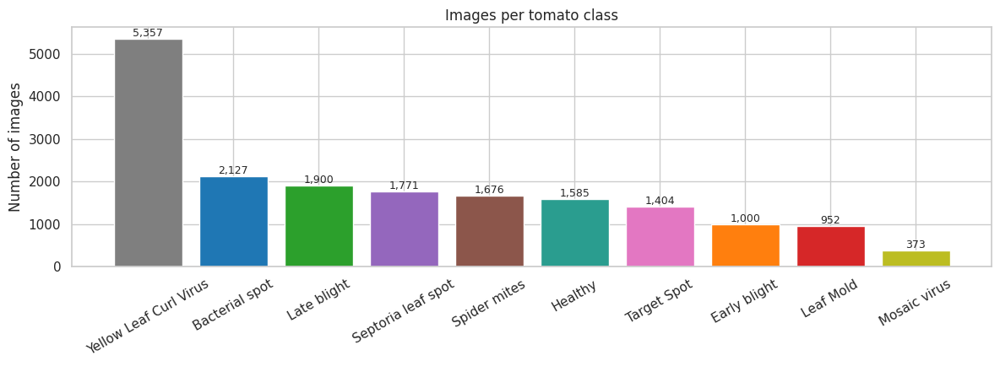

Largest class : Tomato___Tomato_Yellow_Leaf_Curl_Virus (5,357)
Smallest class: Tomato___Tomato_mosaic_virus (373)
Imbalance ratio: 14.36x | share of diseased images: 91%


In [12]:
counts = inventory.label.value_counts().reindex(SELECTED_CLASSES)
counts = counts.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(SHORT[counts.index].values, counts.values, color=[PALETTE[c] for c in counts.index])
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Number of images"); ax.set_title("Images per tomato class"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

imbalance = counts.max() / counts.min()
print(f"Largest class : {counts.idxmax()} ({counts.max():,})")
print(f"Smallest class: {counts.idxmin()} ({counts.min():,})")
print(f"Imbalance ratio: {imbalance:.2f}x | share of diseased images: {(~inventory.is_healthy).mean():.0%}")

The ten classes are strongly imbalanced. Yellow Leaf Curl Virus is by far the largest class and mosaic virus the smallest, a gap of more than 10×. Nine of the ten classes are diseases, so a model biased toward the big classes could post high *accuracy* while missing rare diseases almost entirely. This motivated the stratified split in Section 2, which ensures that even the smallest classes are represented in the validation and test sets. It also means that accuracy alone would be misleading. Class weights will therefore be applied during training, and macro-averaged F1, which gives every disease equal weight, will be reported alongside accuracy.

### 3.2 Image sizes and examples

Image sizes (width, height):
 width  height
256    256       18145


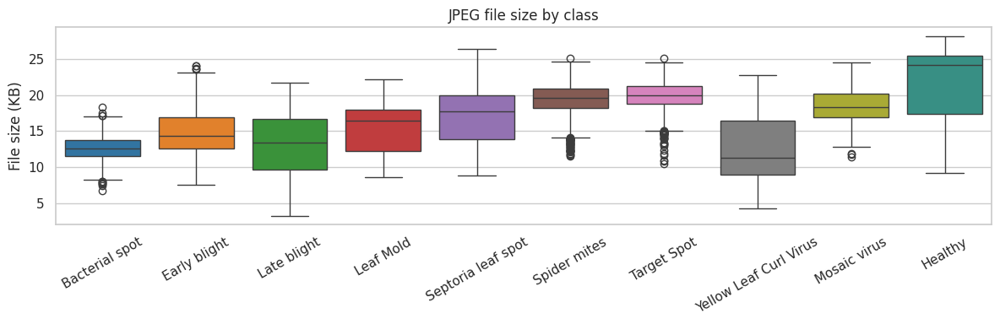

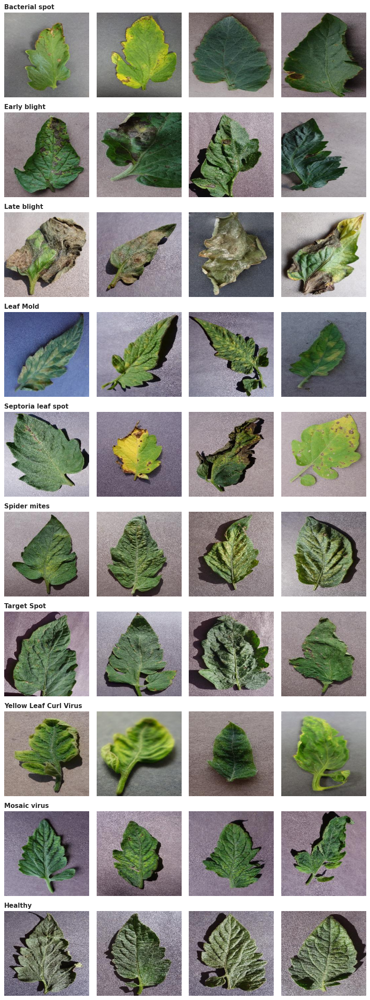

In [16]:
geom = inventory.groupby(["width", "height"]).size()
print("Image sizes (width, height):\n", geom.to_string())

SHORT_PALETTE = {SHORT[c]: PALETTE[c] for c in SELECTED_CLASSES}

fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=inventory.assign(kb=inventory.bytes / 1024, cls=inventory.label.map(SHORT)),
            x="cls", y="kb", hue="cls", palette=SHORT_PALETTE, legend=False, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("File size (KB)"); ax.set_title("JPEG file size by class")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(SELECTED_CLASSES), 4, figsize=(9, 2.4 * len(SELECTED_CLASSES)))
for r, cls in enumerate(SELECTED_CLASSES):
    for c, p in enumerate(inventory[inventory.label == cls].path.sample(4, random_state=SEED)):
        axes[r, c].imshow(Image.open(p).convert("RGB")); axes[r, c].axis("off")
    axes[r, 0].set_title(SHORT[cls], loc="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

All 18,145 images are 256×256, so resizing to 224×224 needs no cropping. File size, which roughly reflects the amount of fine detail, varies by class. Healthy leaves have the largest files, because they are sharp close-ups with visible veins and surface hairs. Yellow Leaf Curl Virus has among the smallest, as many of its images are out of focus. The samples show distinct symptoms: brown lesions (early blight, target spot, late blight), small dark spots (Septoria, bacterial spot), yellow patches or stippling (leaf mold, spider mites), and yellowing, curling or mottling (the two viruses). Since image sharpness differs between classes, the model could partly learn photographic conditions rather than symptoms, which is a risk for field photos.

### 3.3 Extracting features from the pixels
Since images have no tabular columns, numeric features are extracted from a sample of 200 images per class (resized to 128×128):

| Feature | Description |
|---|---|
| `mean_hue`, `green_ratio` | average hue of leaf pixels; share of green in RGB |
| `lesion_ratio` | share of leaf pixels that are yellow or brown (hue < 60°) |
| `brightness`, `contrast` | mean and standard deviation of pixel intensity |
| `edge_density` | share of pixels detected as edges (Canny), a measure of texture |

In [30]:
def pixel_features(path):
    img = cv2.resize(cv2.imread(path), (128, 128))
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    b, g, r = [img[..., i].astype(np.float32) for i in range(3)]
    leaf = (hsv[..., 1] > 50) & (hsv[..., 2] > 40)     # coloured pixels (excludes grey background)
    hue = hsv[..., 0].astype(np.float32) * 2.0         # OpenCV hue is 0-179, convert to degrees
    edges = cv2.Canny(gray, 100, 200)
    return {"mean_hue": float(hue[leaf].mean()) if leaf.any() else np.nan,
            "green_ratio": float(np.mean(g / (r + g + b + 1e-6))),
            "lesion_ratio": float((leaf & (hue < 60)).sum() / max(leaf.sum(), 1)),
            "brightness": float(hsv[..., 2].mean()),
            "contrast": float(gray.std()),
            "edge_density": float((edges > 0).mean())}

FEATURES = ["mean_hue", "green_ratio", "lesion_ratio", "brightness", "contrast", "edge_density"]
feat_sample = sample_per_class(inventory, 200)

with ThreadPoolExecutor(max_workers=8) as ex:
    feats = list(tqdm(ex.map(pixel_features, feat_sample.path), total=len(feat_sample), desc="Features"))

feat_df = pd.concat([feat_sample[["label", "disease", "is_healthy"]].reset_index(drop=True),
                     pd.DataFrame(feats)], axis=1)
feat_df["class"] = feat_df.label.map(SHORT)
feat_df["status"] = np.where(feat_df.is_healthy, "Healthy", "Diseased")
feat_df.groupby("class")[FEATURES].mean().reindex(SHORT[SELECTED_CLASSES]).round(3)

Features:   0%|          | 0/2000 [00:00<?, ?it/s]

,mean_hue,green_ratio,lesion_ratio,brightness,contrast,edge_density
Bacterial spot,108.292,0.369,0.083,112.354,32.349,0.054
Early blight,98.439,0.364,0.153,119.643,43.452,0.108
Late blight,82.273,0.347,0.244,124.318,38.503,0.085
Leaf Mold,126.430,0.352,0.028,130.166,34.554,0.085
Septoria leaf spot,99.036,0.358,0.101,144.705,34.718,0.090
Spider mites,85.159,0.354,0.171,129.674,40.822,0.113
Target Spot,109.510,0.354,0.023,127.977,41.762,0.135
Yellow Leaf Curl Virus,83.531,0.389,0.097,124.401,33.602,0.084
Mosaic virus,118.387,0.343,0.004,129.571,30.766,0.094
Healthy,95.547,0.352,0.010,124.652,32.384,0.129


Colour features are computed on coloured pixels only (saturation > 50), which excludes the grey background. This is an approximation: some dull or dark leaf areas are also excluded, so `lesion_ratio` may slightly underestimate lesion coverage.

### 3.4 Feature 1 - leaf colour

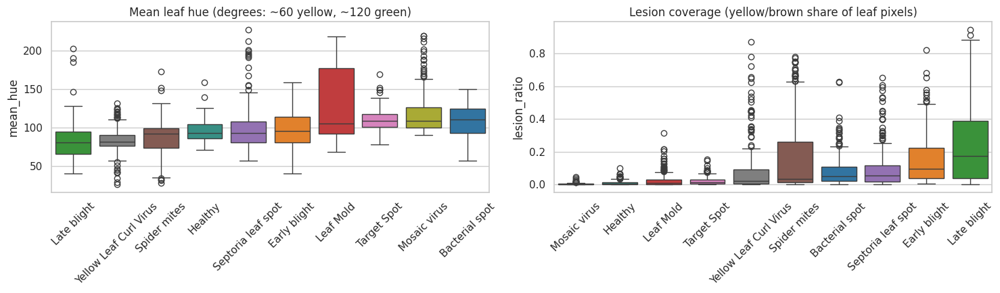

                        mean_hue  green_ratio  lesion_ratio
class                                                      
Bacterial spot           110.707        0.368         0.049
Early blight              95.886        0.363         0.095
Late blight               80.366        0.352         0.176
Leaf Mold                105.191        0.354         0.010
Septoria leaf spot        92.823        0.359         0.056
Spider mites              91.598        0.353         0.034
Target Spot              108.368        0.354         0.013
Yellow Leaf Curl Virus    81.529        0.389         0.019
Mosaic virus             108.515        0.343         0.002
Healthy                   92.465        0.352         0.003


In [33]:
ORDER = list(SHORT[SELECTED_CLASSES])

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
hue_order = feat_df.groupby("class").mean_hue.median().sort_values().index
sns.boxplot(data=feat_df, x="class", y="mean_hue", hue="class", order=hue_order,
            palette=SHORT_PALETTE, legend=False, ax=ax[0])
ax[0].set_title("Mean leaf hue (degrees: ~60 yellow, ~120 green)")

lesion_order = feat_df.groupby("class").lesion_ratio.median().sort_values().index
sns.boxplot(data=feat_df, x="class", y="lesion_ratio", hue="class", order=lesion_order,
            palette=SHORT_PALETTE, legend=False, ax=ax[1])
ax[1].set_title("Lesion coverage (yellow/brown share of leaf pixels)")

for a in ax:
    a.set_xlabel(""); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

print(feat_df.groupby("class")[["mean_hue", "green_ratio", "lesion_ratio"]].median().reindex(ORDER).round(3))

Lesion coverage is the clearest colour-based signal. Late blight has by far the highest median (0.18), followed by early blight (0.10), Septoria (0.06) and bacterial spot (0.05), which matches the large brown dead areas and spots seen in the sample images. Healthy leaves and mosaic virus are almost zero (≈0.003), with leaf mold and target spot also low. Hue is less informative. Late blight (80°) and Yellow Leaf Curl Virus (82°) are the most yellow, consistent with dead tissue and yellowing, but healthy leaves (92°) sit in the middle of the range rather than at the green end, since they are photographed as dull grey-green. Leaf mold shows a very wide hue spread, likely because some of its photos have a bluish background. Green ratio barely differs between classes (0.34–0.39) and is not useful on its own.

Overall, colour separates some diseases (especially the blights) from healthy leaves, but most classes overlap heavily, so colour alone cannot identify the disease. The model will also need texture and shape, and the classes with similar colour profiles are expected to be the most confused. Since colour still carries useful information, the augmentation in Section 4 changes geometry and contrast but does not shift hue.

### 3.5 Feature 2 - brightness and contrast

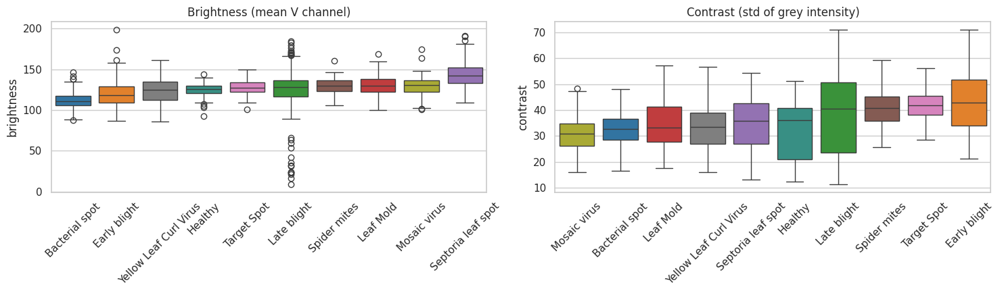

                        brightness  contrast
class                                       
Bacterial spot               110.9      32.6
Early blight                 118.0      42.9
Late blight                  128.6      40.5
Leaf Mold                    130.3      33.1
Septoria leaf spot           142.0      35.8
Spider mites                 129.7      40.7
Target Spot                  127.4      41.9
Yellow Leaf Curl Virus       125.2      33.4
Mosaic virus                 130.7      30.9
Healthy                      125.4      36.0


In [35]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, col, title in [(ax[0], "brightness", "Brightness (mean V channel)"),
                      (ax[1], "contrast", "Contrast (std of grey intensity)")]:
    order = feat_df.groupby("class")[col].median().sort_values().index
    sns.boxplot(data=feat_df, x="class", y=col, hue="class", order=order,
                palette=SHORT_PALETTE, legend=False, ax=a)
    a.set_title(title); a.set_xlabel(""); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

print(feat_df.groupby("class")[["brightness", "contrast"]].median().reindex(ORDER).round(1))

Brightness is fairly similar across classes, with most medians between 118 and 131. The exceptions are bacterial spot, the darkest (111), and Septoria leaf spot, the brightest (142). Late blight has a median close to the others but a long tail of very dark outliers, likely images with large areas of dead, blackened tissue. Contrast varies more: early blight (43), target spot (42), spider mites (41) and late blight (40) have the highest contrast, consistent with dark lesions on lighter tissue, while mosaic virus (31) and bacterial spot (33) are the most uniform. The overlap between classes is large, however, so neither brightness nor contrast can separate the diseases on its own.

The narrow brightness range reflects the controlled lab setting: one leaf per image, a plain background and consistent lighting. Standard normalisation is therefore sufficient, and no per-image histogram equalisation is needed. It also means that field photos, with sunlight, shadows and cluttered backgrounds, may look quite different from the training data. Random contrast and zoom augmentation partly simulate this, and retraining with real field images would further reduce the gap.

### 3.6 Feature 3 — texture (edge density)

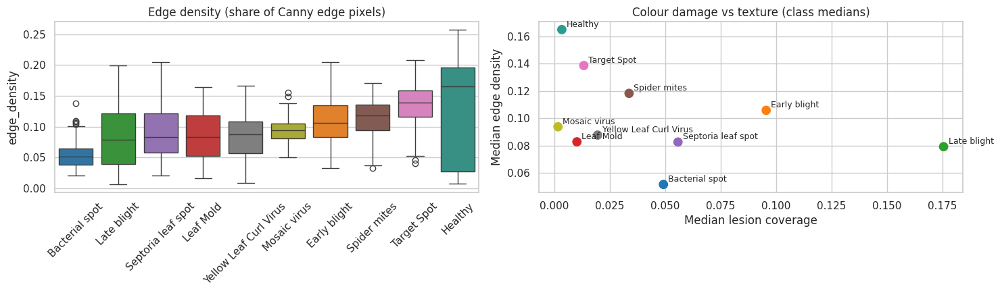

                        lesion_ratio  edge_density
class                                             
Bacterial spot                 0.049         0.052
Early blight                   0.095         0.106
Late blight                    0.176         0.079
Leaf Mold                      0.010         0.083
Septoria leaf spot             0.056         0.083
Spider mites                   0.034         0.118
Target Spot                    0.013         0.139
Yellow Leaf Curl Virus         0.019         0.088
Mosaic virus                   0.002         0.094
Healthy                        0.003         0.165


In [37]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

order = feat_df.groupby("class").edge_density.median().sort_values().index
sns.boxplot(data=feat_df, x="class", y="edge_density", hue="class", order=order,
            palette=SHORT_PALETTE, legend=False, ax=ax[0])
ax[0].set_title("Edge density (share of Canny edge pixels)")
ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=45)

med = feat_df.groupby("class")[["lesion_ratio", "edge_density"]].median()
ax[1].scatter(med.lesion_ratio, med.edge_density, s=80, c=[SHORT_PALETTE[c] for c in med.index])
for name, row in med.iterrows():
    ax[1].annotate(name, (row.lesion_ratio, row.edge_density), xytext=(5, 3),
                   textcoords="offset points", fontsize=9)
ax[1].set_xlabel("Median lesion coverage"); ax[1].set_ylabel("Median edge density")
ax[1].set_title("Colour damage vs texture (class medians)")

plt.tight_layout(); plt.show()
print(med.reindex(ORDER).round(3))

Edge density does not follow a simple "diseased leaves have more texture" pattern. Healthy leaves have the highest median (0.165), followed by target spot (0.139) and spider mites (0.118), while bacterial spot has the lowest (0.052). This matches the file-size results in Section 3.2: the healthy images are sharp close-ups where veins and surface hairs produce many edges, whereas many bacterial spot and Yellow Leaf Curl Virus images are softer or less detailed. Edge density therefore reflects image sharpness and leaf surface as much as disease symptoms.

The right-hand plot combines both features. Late blight stands apart through colour damage (high lesion coverage), and healthy leaves and target spot stand apart through texture. Early blight sits moderately high on both. Mosaic virus, leaf mold, Yellow Leaf Curl Virus and Septoria cluster together, with similar values on both features, so these classes may be the hardest to distinguish.

**EDA conclusion.** None of the hand-crafted features separates all ten classes on its own: each disease is better described by a combination of colour, texture and shape. This supports using a convolutional neural network, which learns such combinations directly from the pixels, with a backbone pretrained on ImageNet that already detects colour and texture patterns. The analysis also shows that image sharpness differs between classes, so the model could partly rely on photographic conditions rather than symptoms. This should be considered when interpreting the test results and when applying the model to field photos.

In [40]:
# save summary statistics of the dataset
stats = {
    "classes": SELECTED_CLASSES, "short_names": SHORT.to_dict(),
    "n_images": int(len(inventory)), "n_classes": len(SELECTED_CLASSES),
    "class_counts": {k: int(v) for k, v in counts.items()},
    "split_counts": {k: int(v) for k, v in inventory.split.value_counts().items()},
    "feature_means_by_class": feat_df.groupby("label")[FEATURES].mean().round(4).to_dict(orient="index"),
    "feature_samples": feat_df.sample(min(len(feat_df), 1200), random_state=SEED)[
        ["label", "status", *FEATURES]].round(4).to_dict(orient="records"),
}
with open(MODELS_DIR / "dataset_stats.json", "w") as f:
    json.dump(stats, f)
print("Saved", MODELS_DIR / "dataset_stats.json")

Saved /kaggle/working/models/dataset_stats.json


## 4. Preprocessing
The same preprocessing is applied to every image used for training, evaluation and prediction:

1. Decode the image as RGB (3 channels).
2. Resize to 224×224, the input size expected by MobileNetV2.
3. Normalise pixel values from [0, 255] to [-1, 1] with a `Rescaling` layer inside the model. This is equivalent to MobileNetV2's own preprocessing, and means the saved model accepts plain resized images.
4. Augment the training set only. Since the dataset version without augmentation is used, augmentation is applied during training, as Keras layers placed in front of the model so that it runs on the GPU:
   - random flips, rotation (up to ±54°), zoom (±10%) and translation (±10%), since leaf orientation and position carry no meaning;
   - random brightness and contrast changes (±20%) to simulate the varied lighting of field photos, as Section 3.5 showed that the lab images have a narrow brightness range;
   - no hue or colour shifts (unlike the PCA colour augmentation used by the dataset creators), because Section 3.4 showed that colour carries useful disease information.

   Each augmentation is applied with a random strength for every image in every epoch. Gaussian blur and noise were also tested but removed (see Section 5.3).
5. Encode labels as one-hot vectors for categorical cross-entropy.
6. Compute class weights to compensate for the class imbalance found in Section 3.1.
7. Use `tf.data` with in-memory caching, so each JPEG is decoded only once, and prefetching, so data loading does not slow down training.

In [75]:
def load_split(directory, shuffle):
    return keras.utils.image_dataset_from_directory(
        directory, labels="inferred", label_mode="categorical", image_size=IMG_SIZE,
        batch_size=BATCH_SIZE, shuffle=shuffle, seed=SEED, interpolation="bilinear")

raw_train = load_split(TRAIN_DIR, shuffle=True)
raw_val   = load_split(VAL_DIR, shuffle=False)
raw_test  = load_split(TEST_DIR, shuffle=False)
CLASS_NAMES = raw_train.class_names
NUM_CLASSES = len(CLASS_NAMES)
assert CLASS_NAMES == raw_val.class_names == raw_test.class_names
print(NUM_CLASSES, "classes")

Found 12701 files belonging to 10 classes.
Found 2722 files belonging to 10 classes.
Found 2722 files belonging to 10 classes.
10 classes


In [76]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomContrast(0.20),
    layers.RandomBrightness(0.20, value_range=(0, 255)),
], name="augmentation")

def to_uint8(x, y): return tf.cast(x, tf.uint8), y
def to_float(x, y): return tf.cast(x, tf.float32), y

# decoded images are cached in memory (uint8) so JPEG decoding happens only once
train_ds = raw_train.map(to_uint8).cache().shuffle(len(raw_train)).map(to_float).prefetch(AUTOTUNE)
val_ds   = raw_val.map(to_uint8).cache().map(to_float).prefetch(AUTOTUNE)
test_ds  = raw_test.map(to_uint8).cache().map(to_float).prefetch(AUTOTUNE)

def take_fraction(ds, frac):
    return ds.take(max(1, int(len(ds) * frac)))

def with_augmentation(model):
    # training wrapper: augmentation (GPU) -> model; only `model` is saved
    inp = keras.Input(shape=IMG_SIZE + (3,))
    return keras.Model(inp, model(augmentation(inp)), name=f"{model.name}_trainer")

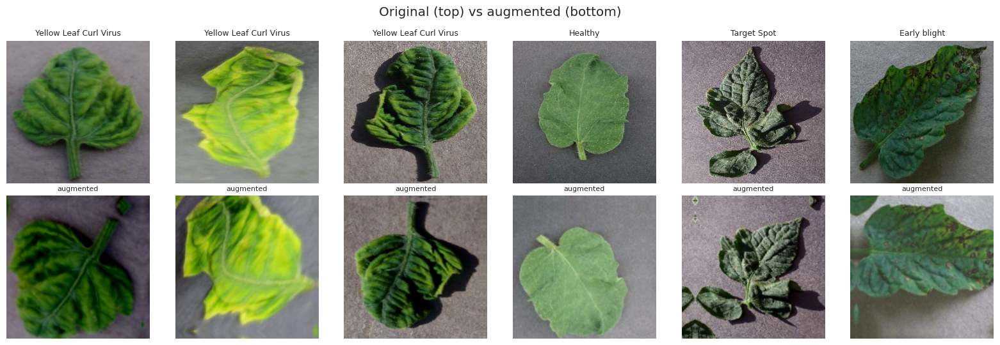

Model input: shape=(32, 224, 224, 3), dtype=<dtype: 'float32'>, min=-1.00, max=0.98


In [77]:
# Visual check of the preprocessing and augmentation
imgs, lbls = next(iter(raw_train))
fig, axes = plt.subplots(2, 6, figsize=(16, 5.5))
for i in range(6):
    axes[0, i].imshow(imgs[i].numpy().astype("uint8")); axes[0, i].set_title(SHORT[CLASS_NAMES[np.argmax(lbls[i])]], fontsize=9)
    aug = augmentation(imgs[i:i+1], training=True)[0].numpy()
    axes[1, i].imshow(np.clip(aug, 0, 255).astype("uint8")); axes[1, i].set_title("augmented", fontsize=8)
for a in axes.flat: a.axis("off")
plt.suptitle("Original (top) vs augmented (bottom)"); plt.tight_layout(); plt.show()

x = imgs / 127.5 - 1
print(f"Model input: shape={tuple(x.shape)}, dtype={x.dtype}, min={float(tf.reduce_min(x)):.2f}, max={float(tf.reduce_max(x)):.2f}")

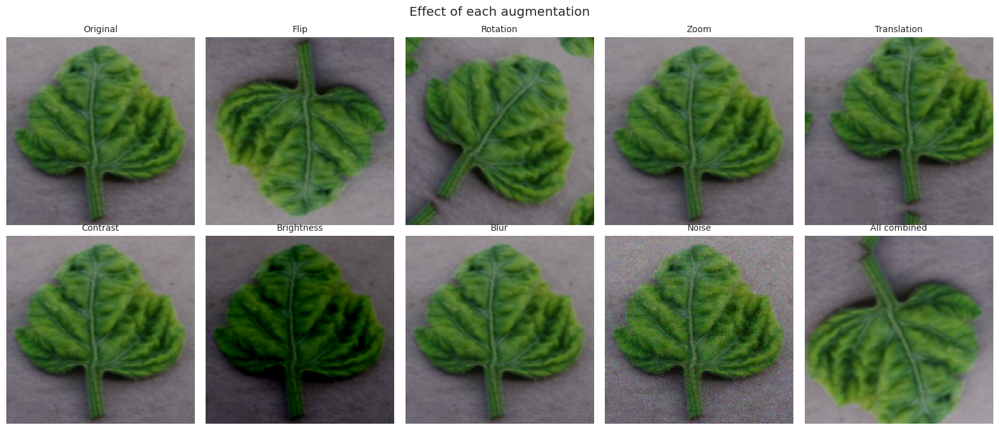

In [80]:
img = imgs[0:1]
steps = [("Original", None),
         ("Flip", layers.RandomFlip("horizontal_and_vertical")),
         ("Rotation", layers.RandomRotation(0.15)),
         ("Zoom", layers.RandomZoom(0.10)),
         ("Translation", layers.RandomTranslation(0.10, 0.10)),
         ("Contrast", layers.RandomContrast(0.20)),
         ("Brightness", layers.RandomBrightness(0.20, value_range=(0, 255))),
         ("Blur", layers.RandomGaussianBlur(factor=0.5, sigma=(0.1, 1.0), value_range=(0, 255))),
         ("Noise", keras.Sequential([layers.Rescaling(1/255), layers.GaussianNoise(0.05), layers.Rescaling(255)])),
         ("All combined", augmentation)]

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, (name, layer) in zip(axes.flat, steps):
    out = img if layer is None else layer(img, training=True)
    ax.imshow(np.clip(out[0].numpy(), 0, 255).astype("uint8")); ax.set_title(name, fontsize=10); ax.axis("off")
plt.suptitle("Effect of each augmentation"); plt.tight_layout(); plt.show()

In [81]:
y_train_int = train_df.label.map({c: i for i, c in enumerate(CLASS_NAMES)}).values
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train_int)
CLASS_WEIGHTS = {i: float(w) for i, w in enumerate(weights)}

pd.DataFrame({"train images": train_df.label.value_counts().reindex(CLASS_NAMES).values,
              "class weight": weights.round(2)},
             index=SHORT[CLASS_NAMES].values).sort_values("class weight", ascending=False)

,train images,class weight
Mosaic virus,261,4.87
Leaf Mold,666,1.91
Early blight,700,1.81
Target Spot,983,1.29
Healthy,1109,1.15
Spider mites,1173,1.08
Septoria leaf spot,1240,1.02
Late blight,1330,0.95
Bacterial spot,1489,0.85
Yellow Leaf Curl Virus,3750,0.34


## 5. Model creation

### 5.1 Baseline: a vanilla CNN
A small CNN trained from scratch with default settings (no pretrained weights, no regularisation, no class weights). It is the reference point that shows how much the optimisation techniques in 5.2–5.3 add.

In [82]:
def build_baseline(num_classes):
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = layers.Rescaling(1/255)(inputs)
    for filters in (32, 64, 128):
        x = layers.Conv2D(filters, 3, activation="relu", padding="same")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="baseline_cnn")
    model.compile(optimizer="sgd", loss="categorical_crossentropy", metrics=["accuracy"])
    return model

baseline = build_baseline(NUM_CLASSES)
baseline.summary()
t0 = time.time()
baseline_history = baseline.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_BASELINE, verbose=2)
print(f"Baseline trained in {(time.time()-t0)/60:.1f} min")

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
397/397 - 33s - 84ms/step - accuracy: 0.2874 - loss: 2.1428 - val_accuracy: 0.2954 - val_loss: 2.0973
Epoch 2/8
397/397 - 23s - 58ms/step - accuracy: 0.2953 - loss: 2.0640 - val_accuracy: 0.2954 - val_loss: 1.9847
Epoch 3/8
397/397 - 23s - 57ms/step - accuracy: 0.3290 - loss: 1.8867 - val_accuracy: 0.3729 - val_loss: 1.8093
Epoch 4/8
397/397 - 23s - 58ms/step - accuracy: 0.3730 - loss: 1.7803 - val_accuracy: 0.3927 - val_loss: 1.7085
Epoch 5/8
397/397 - 23s - 58ms/step - accuracy: 0.4067 - loss: 1.6976 - val_accuracy: 0.4291 - val_loss: 1.6559
Epoch 6/8
397/397 - 23s - 58ms/step - accuracy: 0.4348 - loss: 1.6039 - val_accuracy: 0.4515 - val_loss: 1.5504
Epoch 7/8
397/397 - 23s - 58ms/step - accuracy: 0.4558 - loss: 1.5314 - val_accuracy: 0.4750 - val_loss: 1.4705
Epoch 8/8
397/397 - 23s - 58ms/step - accuracy: 0.4767 - loss: 1.4891 - val_accuracy: 0.4783 - val_loss: 1.4618
Baseline trained in 3.2 min


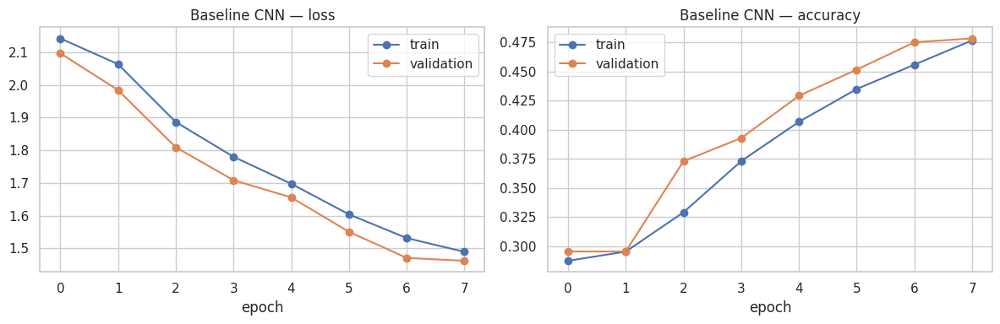

In [83]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, metric in zip(ax, ["loss", "accuracy"]):
    a.plot(baseline_history.history[metric], marker="o", label="train")
    a.plot(baseline_history.history[f"val_{metric}"], marker="o", label="validation")
    a.set_title(f"Baseline CNN — {metric}"); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

### 5.2 Optimised model: MobileNetV2 transfer learning
The optimised model uses MobileNetV2 pre-trained on ImageNet as a feature extractor, with a new classification head for the 10 classes. The following optimisation techniques are used:

| Technique | Purpose |
|---|---|
| Pre-trained model (MobileNetV2, ImageNet) | reuses features that already detect edges, textures and colours; small (≈3.5M parameters), so prediction is fast |
| Data augmentation (Section 4) | increases variety in the training data and reduces overfitting |
| Adam optimiser | adaptive learning rates, which converge faster than SGD |
| L2 regularisation (1e-4) on the dense layer | penalises large weights to reduce overfitting |
| Dropout (tuned) | randomly drops units during training to reduce overfitting |
| Batch normalisation | stabilises training of the head |
| Label smoothing (0.1) | prevents over-confident predictions |
| Class weights | compensate for class imbalance |
| Early stopping (best weights restored) | stops training when validation loss stops improving |
| Learning-rate reduction on plateau | halves the learning rate when progress stalls |
| Hyperparameter search (Section 5.2.1) | selects the learning rate and dropout using validation macro-F1 |
| Fine-tuning (Section 5.3) | trains the head first, then unfreezes the top 30 backbone layers at a 100× lower learning rate |

In [84]:
def build_model(num_classes, dropout=0.3, l2=1e-4, dense_units=256):
    base = mobilenet_v2.MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = keras.Input(shape=IMG_SIZE + (3,), name="image")
    x = layers.Rescaling(1/127.5, offset=-1, name="normalise")(inputs)
    x = base(x, training=False)          # keep the backbone's BatchNorm layers in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(dense_units, activation="relu", kernel_regularizer=regularizers.l2(l2))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name=MODEL_NAME)

def compile_model(model, learning_rate):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
        metrics=["accuracy",
                 keras.metrics.Precision(name="precision"),
                 keras.metrics.Recall(name="recall"),
                 keras.metrics.F1Score(average="macro", name="f1"),
                 keras.metrics.AUC(name="auc"),
                 keras.metrics.TopKCategoricalAccuracy(k=3, name="top3_acc")])

def get_callbacks(patience=3):
    return [callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, verbose=1),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1)]

def predict_dataset(model, ds):
    y_true, y_prob = [], []
    for xb, yb in ds:
        y_prob.append(model.predict_on_batch(xb)); y_true.append(np.argmax(yb.numpy(), axis=1))
    return np.concatenate(y_true), np.concatenate(y_prob)

#### 5.2.1 Hyperparameter search
A small grid over **learning rate × dropout**. Each configuration trains the head for a few epochs on 25% of the training batches and is scored on **validation macro-F1**. The best configuration is used for the full training run.

In [85]:
grid = [{"learning_rate": lr, "dropout": d} for lr in (1e-3, 3e-4) for d in (0.2, 0.4)]
search_results = []
search_train = take_fraction(train_ds, 0.25)

for params in grid:
    keras.backend.clear_session(); tf.random.set_seed(SEED)
    m = build_model(NUM_CLASSES, dropout=params["dropout"])
    t = with_augmentation(m)
    compile_model(t, params["learning_rate"])
    t.fit(search_train, validation_data=val_ds, epochs=HPARAM_EPOCHS, class_weight=CLASS_WEIGHTS, verbose=0)
    yt, yp = predict_dataset(m, val_ds)
    res = {**params,
           "val_accuracy": accuracy_score(yt, yp.argmax(1)),
           "val_macro_f1": f1_score(yt, yp.argmax(1), average="macro")}
    search_results.append(res); print(res)

search_df = pd.DataFrame(search_results).sort_values("val_macro_f1", ascending=False)
best_params = {"learning_rate": float(search_df.iloc[0].learning_rate), "dropout": float(search_df.iloc[0].dropout)}
display(search_df)
print("Selected hyperparameters:", best_params)

{'learning_rate': 0.001, 'dropout': 0.2, 'val_accuracy': 0.7582659808963997, 'val_macro_f1': 0.7216647681060366}
{'learning_rate': 0.001, 'dropout': 0.4, 'val_accuracy': 0.7821454812637766, 'val_macro_f1': 0.705724505314753}
{'learning_rate': 0.0003, 'dropout': 0.2, 'val_accuracy': 0.7843497428361499, 'val_macro_f1': 0.7315290933196057}
{'learning_rate': 0.0003, 'dropout': 0.4, 'val_accuracy': 0.7560617193240264, 'val_macro_f1': 0.6983907299691167}


,learning_rate,dropout,val_accuracy,val_macro_f1
2,0.0003,0.2,0.784350,0.731529
0,0.0010,0.2,0.758266,0.721665
1,0.0010,0.4,0.782145,0.705725
3,0.0003,0.4,0.756062,0.698391


Selected hyperparameters: {'learning_rate': 0.0003, 'dropout': 0.2}


### 5.3 Training: phase 1 (frozen backbone) → phase 2 (fine-tuning)

In [86]:
keras.backend.clear_session(); tf.random.set_seed(SEED)
model = build_model(NUM_CLASSES, dropout=best_params["dropout"])
trainer = with_augmentation(model)
compile_model(trainer, best_params["learning_rate"])
model.summary()

t0 = time.time()
hist_head = trainer.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                        class_weight=CLASS_WEIGHTS, callbacks=get_callbacks(), verbose=2)
print(f"Phase 1 done in {(time.time()-t0)/60:.1f} min")

Model: "crop_disease_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalise (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,589,514 (9.88 MB)

 Trainable params: 331,018 (1.26 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

Epoch 1/10
397/397 - 36s - 91ms/step - accuracy: 0.6200 - auc: 0.9224 - f1: 0.5494 - loss: 1.5770 - precision: 0.7671 - recall: 0.4922 - top3_acc: 0.8490 - val_accuracy: 0.7858 - val_auc: 0.9723 - val_f1: 0.7239 - val_loss: 1.1353 - val_precision: 0.8891 - val_recall: 0.6833 - val_top3_acc: 0.9420 - learning_rate: 3.0000e-04
Epoch 2/10
397/397 - 29s - 72ms/step - accuracy: 0.7494 - auc: 0.9682 - f1: 0.6916 - loss: 1.2304 - precision: 0.8495 - recall: 0.6402 - top3_acc: 0.9388 - val_accuracy: 0.8284 - val_auc: 0.9811 - val_f1: 0.7975 - val_loss: 1.0447 - val_precision: 0.9191 - val_recall: 0.7057 - val_top3_acc: 0.9603 - learning_rate: 3.0000e-04
Epoch 3/10
397/397 - 29s - 72ms/step - accuracy: 0.7835 - auc: 0.9757 - f1: 0.7321 - loss: 1.1492 - precision: 0.8802 - recall: 0.6751 - top3_acc: 0.9509 - val_accuracy: 0.8380 - val_auc: 0.9840 - val_f1: 0.7975 - val_loss: 1.0099 - val_precision: 0.9344 - val_recall: 0.7373 - val_top3_acc: 0.9607 - learning_rate: 3.0000e-04
Epoch 4/10
397/397 

In [87]:
# Phase 2: unfreeze the top of MobileNetV2 (last ~30 layers); BatchNorm layers stay frozen
FINE_TUNE_AT = 30
backbone = next(l for l in model.layers if isinstance(l, keras.Model))   # the MobileNetV2 sub-model
backbone.trainable = True
for layer in backbone.layers[:-FINE_TUNE_AT]:
    layer.trainable = False
for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(trainer, best_params["learning_rate"] / 100)   # re-compile after changing trainable layers
print("Trainable parameters:", sum(np.prod(w.shape) for w in model.trainable_weights))

t0 = time.time()
initial_epoch = len(hist_head.history["loss"])
hist_ft = trainer.fit(train_ds, validation_data=val_ds, epochs=initial_epoch + EPOCHS_FINETUNE,
                      initial_epoch=initial_epoch, class_weight=CLASS_WEIGHTS,
                      callbacks=get_callbacks(), verbose=2)
print(f"Phase 2 done in {(time.time()-t0)/60:.1f} min")

Trainable parameters: 1841738
Epoch 11/20
397/397 - 40s - 101ms/step - accuracy: 0.8457 - auc: 0.9878 - f1: 0.8094 - loss: 0.9911 - precision: 0.9208 - recall: 0.7486 - top3_acc: 0.9754 - val_accuracy: 0.8891 - val_auc: 0.9920 - val_f1: 0.8687 - val_loss: 0.8812 - val_precision: 0.9535 - val_recall: 0.8064 - val_top3_acc: 0.9816 - learning_rate: 3.0000e-06
Epoch 12/20
397/397 - 32s - 80ms/step - accuracy: 0.8636 - auc: 0.9900 - f1: 0.8291 - loss: 0.9600 - precision: 0.9273 - recall: 0.7748 - top3_acc: 0.9800 - val_accuracy: 0.8964 - val_auc: 0.9927 - val_f1: 0.8763 - val_loss: 0.8701 - val_precision: 0.9473 - val_recall: 0.8196 - val_top3_acc: 0.9816 - learning_rate: 3.0000e-06
Epoch 13/20
397/397 - 31s - 79ms/step - accuracy: 0.8701 - auc: 0.9904 - f1: 0.8381 - loss: 0.9513 - precision: 0.9350 - recall: 0.7857 - top3_acc: 0.9804 - val_accuracy: 0.8924 - val_auc: 0.9920 - val_f1: 0.8719 - val_loss: 0.8773 - val_precision: 0.9466 - val_recall: 0.8207 - val_top3_acc: 0.9820 - learning_ra

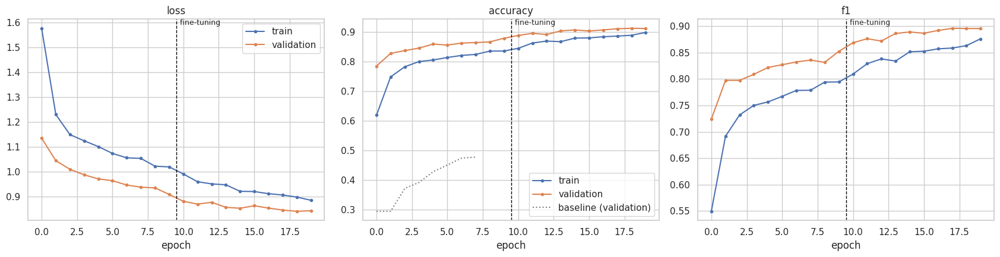

In [90]:
history = {k: hist_head.history[k] + hist_ft.history.get(k, []) for k in hist_head.history}
switch = len(hist_head.history["loss"]) - 0.5

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric in zip(axes, ["loss", "accuracy", "f1"]):
    ax.plot(history[metric], marker="o", ms=3, label="train")
    ax.plot(history[f"val_{metric}"], marker="o", ms=3, label="validation")
    if metric == "accuracy":
        ax.plot(baseline_history.history["val_accuracy"], ls=":", c="grey", label="baseline (validation)")
    ax.axvline(switch, ls="--", c="black", lw=1)
    ax.text(switch + 0.1, ax.get_ylim()[1], " fine-tuning", va="top", fontsize=9)
    ax.set_title(metric); ax.set_xlabel("epoch")
axes[0].legend(loc="upper right"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

After removing blur and noise, validation accuracy reached ≈0.91 and macro-F1 ≈0.90, compared with ≈0.43 for the baseline CNN. Validation scores are slightly higher than training scores because training metrics are computed on augmented images with dropout active, which makes the task harder; this also indicates that the model is not overfitting. Fine-tuning (after the dashed line) gives a further steady improvement, and the curves were still rising when training stopped, so longer fine-tuning could improve the results further.

In [89]:
yt_tr, yp_tr = predict_dataset(model, take_fraction(train_ds, 0.2))   # training images, no augmentation
yt_va, yp_va = predict_dataset(model, val_ds)
print("train accuracy (clean images):", round(accuracy_score(yt_tr, yp_tr.argmax(1)), 3))
print("validation accuracy:          ", round(accuracy_score(yt_va, yp_va.argmax(1)), 3))

train accuracy (clean images): 0.923
validation accuracy:           0.913


An initial version also applied Gaussian blur and noise to every training image, to reduce reliance on image sharpness (Sections 3.2, 3.6). This caused a severe mismatch: accuracy on augmented training images reached 0.86, but only 0.50 on the same images without augmentation, matching the validation accuracy (0.51). The frozen backbone produces different features for blurred, noisy images than for clean ones, so blur and noise were removed. With the final augmentation, accuracy on clean training images (0.92) closely matches validation accuracy (0.91), confirming that the model generalises well.

## 6. Model testing and evaluation (held-out test set)
Metrics reported: **accuracy, loss (cross-entropy), precision, recall, F1** (macro and weighted), **top-3 accuracy, ROC-AUC** (one-vs-rest, macro), the **confusion matrix** and a per-class report.

In [91]:
def evaluate_model(model, ds, class_names):
    y_true, y_prob = predict_dataset(model, ds)
    y_pred = y_prob.argmax(1)
    labels = np.arange(len(class_names))
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "loss": log_loss(y_true, np.clip(y_prob, 1e-7, 1), labels=labels),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "precision_weighted": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "top3_accuracy": top_k_accuracy_score(y_true, y_prob, k=3, labels=labels),
        "roc_auc_ovr_macro": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro", labels=labels),
    }
    return {k: float(v) for k, v in metrics.items()}, y_true, y_prob

test_metrics, y_true, y_prob = evaluate_model(model, test_ds, CLASS_NAMES)
y_pred = y_prob.argmax(1)
pd.Series(test_metrics, name="MobileNetV2 (test)").round(4).to_frame()

,MobileNetV2 (test)
accuracy,0.9093
loss,0.3668
precision_macro,0.8842
recall_macro,0.8944
f1_macro,0.8858
precision_weighted,0.9129
recall_weighted,0.9093
f1_weighted,0.9089
top3_accuracy,0.9893
roc_auc_ovr_macro,0.9939


,Baseline CNN,Optimised MobileNetV2
accuracy,0.4879,0.9093
loss,1.4524,0.3668
precision_macro,0.3276,0.8842
recall_macro,0.3080,0.8944
f1_macro,0.2817,0.8858
precision_weighted,0.4141,0.9129
recall_weighted,0.4879,0.9093
f1_weighted,0.4195,0.9089
top3_accuracy,0.7619,0.9893
roc_auc_ovr_macro,0.8494,0.9939


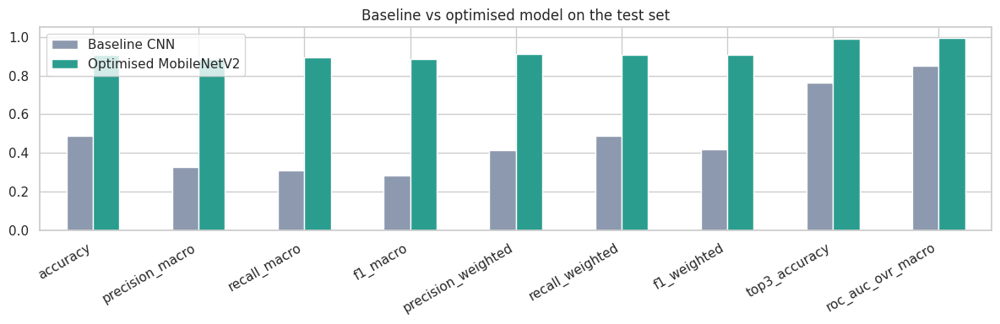

In [92]:
baseline_metrics, _, _ = evaluate_model(baseline, test_ds, CLASS_NAMES)
comparison = pd.DataFrame({"Baseline CNN": baseline_metrics, "Optimised MobileNetV2": test_metrics}).round(4)
display(comparison)

comparison.drop(index="loss").plot(kind="bar", figsize=(12, 4), color=["#8d99ae", "#2a9d8f"])
plt.title("Baseline vs optimised model on the test set"); plt.xticks(rotation=30, ha="right"); plt.ylim(0, 1.05)
plt.tight_layout(); plt.show()

In [93]:
report = classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES,
                               digits=3, zero_division=0, output_dict=True)
report_df = pd.DataFrame(report).T
print(classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES),
                            target_names=list(SHORT[CLASS_NAMES]), digits=3, zero_division=0))

                        precision    recall  f1-score   support

        Bacterial spot      0.879     0.937     0.907       319
          Early blight      0.900     0.660     0.762       150
           Late blight      0.914     0.898     0.906       285
             Leaf Mold      0.765     0.958     0.851       143
    Septoria leaf spot      0.904     0.853     0.878       266
          Spider mites      0.878     0.920     0.899       251
           Target Spot      0.814     0.829     0.822       211
Yellow Leaf Curl Virus      0.999     0.949     0.973       803
          Mosaic virus      0.883     0.946     0.914        56
               Healthy      0.904     0.992     0.946       238

              accuracy                          0.909      2722
             macro avg      0.884     0.894     0.886      2722
          weighted avg      0.913     0.909     0.909      2722



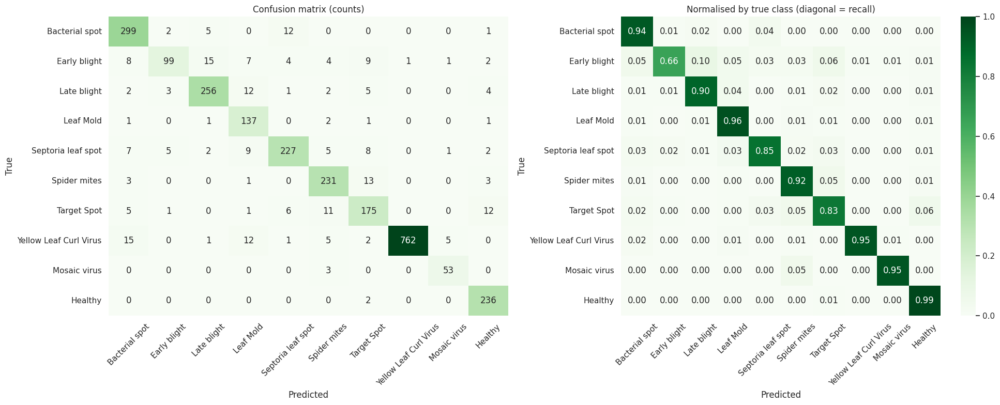

,true,predicted,count
0,Yellow Leaf Curl Virus,Bacterial spot,15
1,Early blight,Late blight,15
2,Spider mites,Target Spot,13
3,Yellow Leaf Curl Virus,Leaf Mold,12
4,Bacterial spot,Septoria leaf spot,12
5,Late blight,Leaf Mold,12
6,Target Spot,Healthy,12
7,Target Spot,Spider mites,11
8,Septoria leaf spot,Leaf Mold,9
9,Early blight,Target Spot,9


In [94]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
short = list(SHORT[CLASS_NAMES])

fig, ax = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=short, yticklabels=short, cmap="Greens", cbar=False, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", xticklabels=short, yticklabels=short, cmap="Greens", vmin=0, vmax=1, ax=ax[1])
ax[1].set_title("Normalised by true class (diagonal = recall)")
for a in ax:
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

# most frequent mistakes
off = cm.copy(); np.fill_diagonal(off, 0)
idx = np.dstack(np.unravel_index(np.argsort(off, axis=None)[::-1], off.shape))[0][:10]
pd.DataFrame([(short[i], short[j], off[i, j]) for i, j in idx if off[i, j] > 0],
             columns=["true", "predicted", "count"])

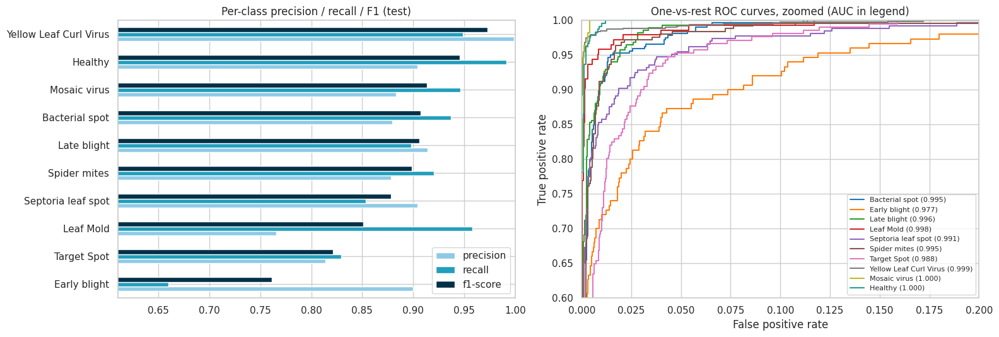

In [97]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))

per_class = report_df.loc[CLASS_NAMES, ["precision", "recall", "f1-score"]].rename(index=dict(zip(CLASS_NAMES, short)))
per_class.sort_values("f1-score").plot(kind="barh", ax=ax[0], color=["#8ecae6", "#219ebc", "#023047"])
ax[0].set_xlim(max(0, per_class.values.min() - 0.05), 1.0)
ax[0].set_title("Per-class precision / recall / F1 (test)"); ax[0].legend(loc="lower right")

y_onehot = np.eye(NUM_CLASSES)[y_true]
for i, name in enumerate(short):
    fpr, tpr, _ = roc_curve(y_onehot[:, i], y_prob[:, i])
    ax[1].plot(fpr, tpr, color=SHORT_PALETTE[name], label=f"{name} ({roc_auc_score(y_onehot[:, i], y_prob[:, i]):.3f})")
ax[1].set_xlim(0, 0.2); ax[1].set_ylim(0.6, 1.0)   # zoom on the top-left corner
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("One-vs-rest ROC curves, zoomed (AUC in legend)"); ax[1].legend(fontsize=8, loc="lower right")

plt.tight_layout(); plt.show()

All classes have a one-vs-rest ROC-AUC of at least 0.977, so the model ranks the correct class highly for almost every image, even when its top prediction is wrong. Per-class performance varies more. Yellow Leaf Curl Virus (F1 ≈ 0.97) and healthy leaves (≈ 0.94) are the easiest classes, while early blight (≈ 0.75) and target spot (≈ 0.82) are the hardest. Early blight has high precision (≈ 0.90) but low recall (≈ 0.66): when the model predicts early blight it is usually right, but it misses about a third of early blight leaves, labelling them as other classes. Leaf mold shows the opposite pattern (precision ≈ 0.77, recall ≈ 0.95), meaning other diseases are often mistaken for leaf mold.

These results only partly match the EDA. Early blight and target spot, both of which produce brown lesions, are the hardest classes, consistent with the colour overlap seen in Section 3.4. However, mosaic virus and Yellow Leaf Curl Virus, which clustered with other classes on the hand-crafted features (Section 3.6), are among the easiest. This shows that the CNN learns shape and pattern cues (such as leaf curling and mottling) that the simple colour and texture features could not capture.

### 6.1 Save the model and its metadata

In [98]:
model.save(MODEL_PATH)                                   # .h5
model.save(MODELS_DIR / f"{MODEL_NAME}.keras")           # native Keras format
with open(MODELS_DIR / "class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f, indent=2)

model_card = {
    "model_name": MODEL_NAME, "version": 1, "created_at": time.strftime("%Y-%m-%dT%H:%M:%S"),
    "input": "RGB image resized to 224x224, pixel values 0-255 (normalisation is inside the model)",
    "img_size": list(IMG_SIZE), "num_classes": NUM_CLASSES, "hyperparameters": best_params,
    "test_metrics": test_metrics, "train_size": int(len(train_df)),
    "history": {k: [float(v) for v in vals] for k, vals in history.items()},
}
with open(MODELS_DIR / "metrics.json", "w") as f:
    json.dump(model_card, f, indent=2)

print("Saved:", *sorted(p.name for p in MODELS_DIR.iterdir()), sep="\n  ")

Saved:
  class_names.json
  crop_disease_mobilenetv2.h5
  crop_disease_mobilenetv2.keras
  dataset_stats.json
  metrics.json


In [102]:
splits = pd.DataFrame({
    "file": inventory.path.map(lambda p: f"{Path(p).parent.name}/{Path(p).name}"),   # <class>/<filename>
    "label": inventory.label,
    "split": inventory.split,
})
splits.to_csv(MODELS_DIR / "splits.csv", index=False)
print(splits.split.value_counts())
splits.head()

split
train         12701
test           2722
validation     2722
Name: count, dtype: int64


,file,label,split
0,Tomato___Bacterial_spot/image (1).JPG,Tomato___Bacterial_spot,train
1,Tomato___Bacterial_spot/image (10).JPG,Tomato___Bacterial_spot,test
2,Tomato___Bacterial_spot/image (100).JPG,Tomato___Bacterial_spot,train
3,Tomato___Bacterial_spot/image (1000).JPG,Tomato___Bacterial_spot,train
4,Tomato___Bacterial_spot/image (1001).JPG,Tomato___Bacterial_spot,test


In [103]:
shutil.make_archive("/kaggle/working/models_export", "zip", MODELS_DIR)
print("Created /kaggle/working/models_export.zip")

Created /kaggle/working/models_export.zip


## 7. Prediction function
The saved model is reloaded and used to predict a single image. Since normalisation is built into the model, the image only needs to be converted to RGB and resized to 224×224. The function returns the predicted disease, its confidence and the top-3 classes.

In [99]:
loaded_model = keras.models.load_model(MODEL_PATH, compile=False)
with open(MODELS_DIR / "class_names.json") as f:
    loaded_classes = json.load(f)

def preprocess_image(image: Image.Image) -> np.ndarray:
    image = image.convert("RGB").resize(IMG_SIZE, Image.BILINEAR)
    return np.asarray(image, dtype=np.float32)[None, ...]      # (1, 224, 224, 3), values 0-255

def predict_image(path_or_image, model=loaded_model, class_names=loaded_classes, top_k=3):
    img = path_or_image if isinstance(path_or_image, Image.Image) else Image.open(path_or_image)
    t0 = time.perf_counter()
    probs = model(preprocess_image(img), training=False).numpy()[0]
    latency = (time.perf_counter() - t0) * 1000
    top = np.argsort(probs)[::-1][:top_k]
    label = class_names[top[0]]
    crop, disease = parse_class(label)
    return {"label": label, "crop": crop, "disease": disease,
            "is_healthy": disease.lower() == "healthy", "confidence": float(probs[top[0]]),
            "top_k": [{"label": class_names[i], "confidence": float(probs[i])} for i in top],
            "latency_ms": round(latency, 1)}

sample = test_df.sample(1, random_state=7).iloc[0]
print("True label:", sample.label)
predict_image(sample.path)

True label: Tomato___Late_blight


{'label': 'Tomato___Late_blight',
 'crop': 'Tomato',
 'disease': 'Late blight',
 'is_healthy': False,
 'confidence': 0.9931422472000122,
 'top_k': [{'label': 'Tomato___Late_blight', 'confidence': 0.9931422472000122},
  {'label': 'Tomato___Early_blight', 'confidence': 0.0034741756971925497},
  {'label': 'Tomato___Leaf_Mold', 'confidence': 0.0019280740525573492}],
 'latency_ms': 242.4}

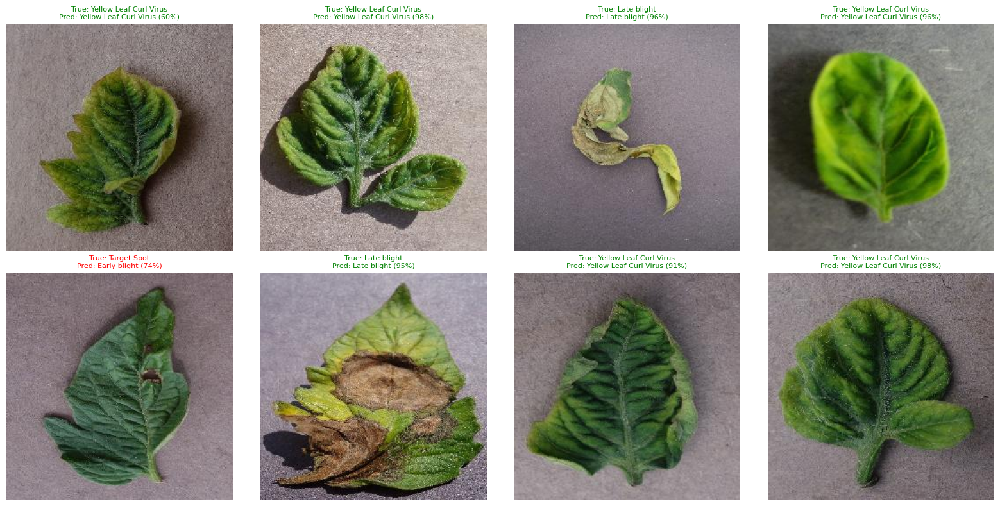

In [100]:
demo = test_df.sample(8, random_state=1)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, row in zip(axes.flat, demo.itertuples()):
    pred = predict_image(row.path)
    ok = pred["label"] == row.label
    ax.imshow(Image.open(row.path).convert("RGB")); ax.axis("off")
    ax.set_title(f"True: {SHORT[row.label]}\nPred: {SHORT[pred['label']]} ({pred['confidence']:.0%})",
                 fontsize=8, color="green" if ok else "red")
plt.tight_layout(); plt.show()

## 8. Retraining with new data
Once deployed, the model should improve as new labelled images become available, for example field photos. Retraining works as follows:

1. Load the current saved model (`crop_disease_mobilenetv2.h5`) and use it as the starting point, so training continues from what the model already learned instead of starting from scratch.
2. Combine the new images with a sample of the original training images (100 per class), so the model does not forget the existing classes (catastrophic forgetting).
3. Apply the same preprocessing and augmentation as in Section 4.
4. Fine-tune for a few epochs at a low learning rate, with early stopping.
5. Evaluate the retrained model on the same test set, and replace the current model only if its macro-F1 is at least as high.

To simulate new uploaded data, 25 images per class are taken from the validation split. The test split is never used for training, to avoid leakage.

In [101]:
def build_retrain_dataset(new_data_dir: Path, replay_df: pd.DataFrame, replay_per_class: int, class_names):
    paths, labels = [], []
    for class_dir in Path(new_data_dir).iterdir():
        if class_dir.is_dir() and class_dir.name in class_names:
            for f in class_dir.iterdir():
                if f.suffix.lower() == ".jpg":
                    paths.append(str(f)); labels.append(class_names.index(class_dir.name))
    n_new = len(paths)
    replay = sample_per_class(replay_df, replay_per_class)
    paths += replay.path.tolist(); labels += [class_names.index(l) for l in replay.label]

    def load(path, label):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        img = tf.image.resize(img, IMG_SIZE)                      # float32, values 0-255
        return img, tf.one_hot(label, len(class_names))

    ds = (tf.data.Dataset.from_tensor_slices((paths, labels)).shuffle(len(paths), seed=SEED)
            .map(load, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE))
    return ds, n_new, len(paths)

def retrain(model_path: Path, new_data_dir: Path, epochs=3, learning_rate=1e-5, replay_per_class=100):
    champion = keras.models.load_model(model_path, compile=False)      # current model
    challenger = keras.models.load_model(model_path, compile=False)    # separate copy, starts from the saved model
    champion_metrics, _, _ = evaluate_model(champion, test_ds, CLASS_NAMES)

    ds, n_new, n_total = build_retrain_dataset(new_data_dir, train_df, replay_per_class, CLASS_NAMES)
    print(f"Retraining on {n_new} new + {n_total - n_new} replay images")
    trainer = with_augmentation(challenger)
    compile_model(trainer, learning_rate)
    trainer.fit(ds, validation_data=val_ds, epochs=epochs, callbacks=get_callbacks(patience=2), verbose=2)

    challenger_metrics, _, _ = evaluate_model(challenger, test_ds, CLASS_NAMES)
    promoted = challenger_metrics["f1_macro"] >= champion_metrics["f1_macro"]
    return challenger, champion_metrics, challenger_metrics, promoted

# Simulate an upload: 25 validation images per class copied into data/uploads/simulated/<class>/
SIM_UPLOAD = UPLOAD_DIR / "simulated"
shutil.rmtree(SIM_UPLOAD, ignore_errors=True)
for row in sample_per_class(val_df, 25).itertuples():
    (SIM_UPLOAD / row.label).mkdir(parents=True, exist_ok=True)
    shutil.copy(row.path, SIM_UPLOAD / row.label / Path(row.path).name)

challenger, champ_m, chall_m, promoted = retrain(MODEL_PATH, SIM_UPLOAD)
display(pd.DataFrame({"current model": champ_m, "retrained model": chall_m}).round(4))
print("Promote retrained model:", promoted)

Retraining on 250 new + 1000 replay images
Epoch 1/3
40/40 - 17s - 431ms/step - accuracy: 0.8896 - auc: 0.9913 - f1: 0.8886 - loss: 0.9061 - precision: 0.9440 - recall: 0.8088 - top3_acc: 0.9824 - val_accuracy: 0.8960 - val_auc: 0.9918 - val_f1: 0.8797 - val_loss: 0.8846 - val_precision: 0.9408 - val_recall: 0.8292 - val_top3_acc: 0.9842 - learning_rate: 1.0000e-05
Epoch 2/3
40/40 - 8s - 188ms/step - accuracy: 0.8776 - auc: 0.9918 - f1: 0.8769 - loss: 0.9117 - precision: 0.9336 - recall: 0.7872 - top3_acc: 0.9848 - val_accuracy: 0.9030 - val_auc: 0.9930 - val_f1: 0.8852 - val_loss: 0.8651 - val_precision: 0.9438 - val_recall: 0.8453 - val_top3_acc: 0.9842 - learning_rate: 1.0000e-05
Epoch 3/3
40/40 - 7s - 187ms/step - accuracy: 0.8976 - auc: 0.9933 - f1: 0.8971 - loss: 0.8841 - precision: 0.9421 - recall: 0.8208 - top3_acc: 0.9840 - val_accuracy: 0.9048 - val_auc: 0.9937 - val_f1: 0.8876 - val_loss: 0.8544 - val_precision: 0.9479 - val_recall: 0.8483 - val_top3_acc: 0.9871 - learning_r

,current model,retrained model
accuracy,0.9093,0.9096
loss,0.3668,0.3660
precision_macro,0.8842,0.8924
recall_macro,0.8944,0.8952
f1_macro,0.8858,0.8903
precision_weighted,0.9129,0.9156
recall_weighted,0.9093,0.9096
f1_weighted,0.9089,0.9102
top3_accuracy,0.9893,0.9871
roc_auc_ovr_macro,0.9939,0.9939


Promote retrained model: True


The retrained model reached a test macro-F1 of 0.890, compared with 0.886 for the current model, with accuracy essentially unchanged (0.910 vs 0.909), so it was promoted. The improvement is very small and within the range of normal training variation, which is expected with only 250 new images and 3 epochs. Top-3 accuracy dropped slightly (0.989 → 0.987), showing that retraining does not improve every metric at once. Since the simulated upload was taken from the validation split, which is also used for early stopping during retraining, the validation scores in this step are slightly optimistic. The test set, which decides promotion, was never used for training. The purpose of this step is to show that the saved model can be loaded, trained further on new data, and replaced only when it performs at least as well on the same test set.

## 9. Summary
The dataset contains 18,145 tomato leaf images in 10 classes (9 diseases and healthy) after removing 14 duplicates. The classes are strongly imbalanced, so a stratified split, class weights and macro-F1 were used. The exploratory analysis showed that lesion coverage is the clearest colour-based signal, especially for the blights, while hue and green ratio separate the classes poorly. It also showed that image sharpness differs between classes, with healthy leaves photographed as sharp close-ups, which the model could exploit.

A baseline CNN trained from scratch reached only about 43% validation accuracy. MobileNetV2 pre-trained on ImageNet, with a tuned learning rate and dropout, L2 regularisation, label smoothing, class weights, early stopping, learning-rate scheduling and fine-tuning, reached a test accuracy of 0.91 and a macro-F1 of 0.89. Blur and noise augmentation were tested but removed, because they caused a large mismatch between augmented and clean images. Most errors involve early blight and target spot, two diseases with similar brown lesions. Finally, the retraining step showed that the saved model can be updated with new data and is only replaced when it performs at least as well.